In [6]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import SGD

In [4]:
np.random.seed(42)
tf.random.set_seed(42)

mnist = tf.keras.datasets.mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_train = X_train / 255.0
X_test = X_test / 255.0

model = models.Sequential([
    layers.Flatten(input_shape=(28, 28)),          # Flatten 28x28 images to 784 vector
    layers.Dense(128, activation='relu'),           # Hidden layer 1
    layers.Dense(64, activation='relu'),            # Hidden layer 2
    layers.Dense(10, activation='softmax')          # Output layer for 10 digit classes
])

In [5]:
sgd_optimizer = SGD(learning_rate=0.01, momentum=0.9)
model.compile(optimizer=sgd_optimizer,
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print("--- Training Feedforward Neural Network ---")
history = model.fit(X_train, y_train, 
                    epochs=15, 
                    batch_size=64, 
                    validation_data=(X_test, y_test))

--- Training Feedforward Neural Network ---
Epoch 1/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8911 - loss: 0.3747 - val_accuracy: 0.9439 - val_loss: 0.1884
Epoch 2/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9534 - loss: 0.1602 - val_accuracy: 0.9619 - val_loss: 0.1272
Epoch 3/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9670 - loss: 0.1126 - val_accuracy: 0.9680 - val_loss: 0.1025
Epoch 4/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9751 - loss: 0.0870 - val_accuracy: 0.9732 - val_loss: 0.0878
Epoch 5/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9808 - loss: 0.0699 - val_accuracy: 0.9760 - val_loss: 0.0808
Epoch 6/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9839 - loss: 0.0578 - val_accuracy: 0.9764 - val_loss: 0.0767
Epoch 7/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9869 - loss: 0.0480 - val_accuracy: 0.9761 - val_loss: 0.0755
Epoch 8/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accu

In [7]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\nFinal Test Loss: {test_loss:.4f}")
print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")


Final Test Loss: 0.0836
Final Test Accuracy: 97.72%


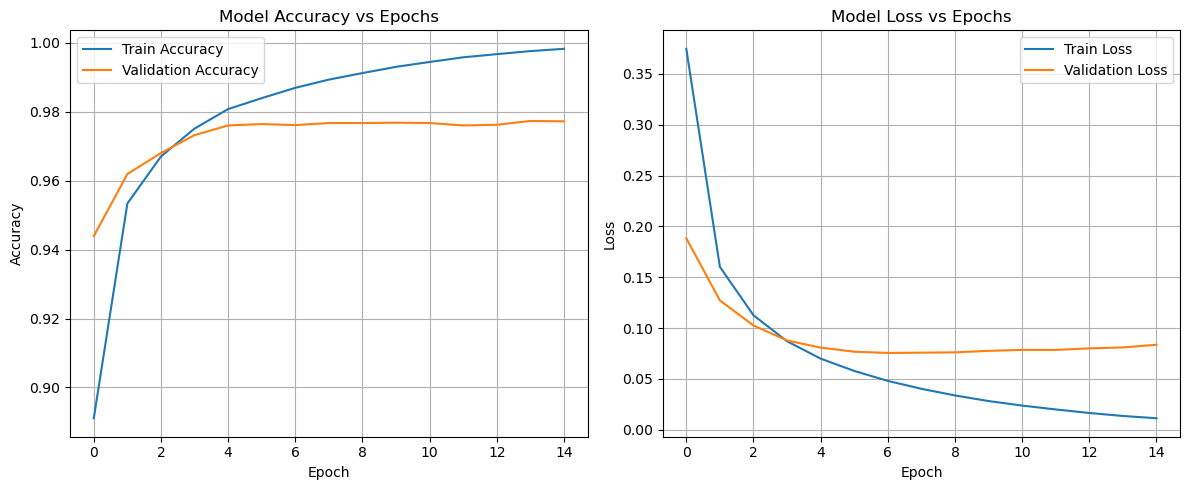

In [8]:
plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy vs Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss vs Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()